# UK Grocery Sales Analysis

**Goal:** Clean a messy dataset of 8,000+ UK grocery transactions (2024–2025) and find what drives revenue.

**Tools:** Python, pandas, NumPy, matplotlib

**Steps:** Load → Explore → Clean → Analyse → Visualise → Insights

# ## 1. Load and explore the data

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("uk_grocery_sales_raw.csv")
df.shape

(8152, 26)

In [4]:
df.head()

,transaction_id,line_id,transaction_date,transaction_time,store_id,city,region,country,postcode_area,channel,...,brand_type,unit_price_gbp,quantity,promotion_type,discount_gbp,net_sales_gbp,vat_rate,payment_method,substitution,transaction_status
0,TXN700131,L000438,2024-08-22,13:13,ST112,Cardiff,Cardiff,Wales,CF10,In-Store,...,Own Label,1.05,1,NaN,0.0,1.05,0%,Gift Card,NaN,Completed
1,TXN701534,L005309,NaN,13:31,ST106,Bristol,South West,England,BS1,In-Store,...,Branded,2.37,6,NaN,0.0,14.22,20%,Credit Card,NaN,Completed
2,TXN700973,L003382,14/01/2025,07:53,ST110,Glasgow,Glasgow,Scotland,G2,Click & Collect,...,Branded,3.19,1,NaN,0.0,3.19,0,Credit Card,No,Completed
3,TXN700029,L000097,2024-02-04,10:33,ST104,Leeds,Yorkshire,England,LS2,Click & Collect,...,Branded,3.4,2,NaN,0.0,6.80,0%,Debit Card,No,Completed
4,TXN701838,L006349,2025-08-24,19:16,ST101,London,Greater London,England,E14,In-Store,...,Own Label,1.05,1,NaN,0.0,1.05,0,Google Pay,NaN,Completed


# 2. Data Cleanng

In [5]:
print("Before:", len(df))
df = df.drop_duplicates()
print("After:", len(df))

Before: 8152
After: 8002


In [6]:
df["unit_price_gbp"] = df["unit_price_gbp"].astype(str).str.replace("\u00a3", "").str.strip()
df["unit_price_gbp"] = pd.to_numeric(df["unit_price_gbp"],errors="coerce")
df["unit_price_gbp"].dtype

dtype('float64')

In [7]:
df["city"] = df["city"].str.strip().str.title()
df["city"] = df["city"].replace({"Greater London": "London","Newcastle Upon Tyne": "Newcastle"})
df["city"].value_counts()

city
Edinburgh     727
London        722
Cardiff       686
Leeds         662
Birmingham    655
Nottingham    642
Bristol       610
Manchester    597
Liverpool     587
Newcastle     553
Belfast       483
Leicester     468
Glasgow       463
Name: count, dtype: int64

In [8]:
df["category"] = df["category"].str.replace(" and ", " & ", case=False)
df["category"] = df["category"].str.strip().str.title()
df["category"].value_counts()

category
Food Cupboard             838
Meat & Fish               836
Household                 836
Snacks & Confectionery    829
Health & Beauty           824
Drinks                    791
Frozen                    769
Fresh Produce             764
Dairy & Eggs              760
Bakery                    755
Name: count, dtype: int64

In [9]:
df["loyalty_member"] = df["loyalty_member"].replace({"Y": "Yes", "yes": "Yes", "TRUE": "Yes", "N": "No"}).fillna("Unknown")
df["payment_method"] = df["payment_method"].str.title().fillna("Unknown")
df["payment_method"] = df["payment_method"].replace({"Chip & Pin": "Chip & PIN","Paypal": "PayPal"})
print(df["loyalty_member"].value_counts())
print(df["payment_method"].value_counts())

loyalty_member
Yes        4720
No         3192
Unknown      90
Name: count, dtype: int64
payment_method
Apple Pay      1409
Credit Card    1351
Debit Card      858
Contactless     750
PayPal          748
Cash            739
Google Pay      722
Chip & PIN      677
Gift Card       628
Unknown         120
Name: count, dtype: int64


In [12]:
print("Missing cities before:" , df["city"].isna().sum())
store_city = df[df["store_id"] != "ONLINE"].groupby("store_id")["city"].agg(lambda s: s.mode()[0])
df["city"] = df["city"].fillna(df["store_id"].map(store_city)).fillna("Unknown")

print("Missing cities after:" , df["city"].isna().sum())
store_city

Missing cities before: 147
Missing cities after: 0


store_id
ST101        London
ST102    Manchester
ST103    Birmingham
ST104         Leeds
ST105     Liverpool
ST106       Bristol
ST107     Leicester
ST108     Newcastle
ST109    Nottingham
ST110       Glasgow
ST111     Edinburgh
ST112       Cardiff
ST113       Belfast
Name: city, dtype: str

In [13]:
df["vat_rate"] = df["vat_rate"].replace({"0": "0%"})
df["promotion_type"] = df["promotion_type"].fillna("No Promotion")
df["age_band"] = df["age_band"].fillna("Unknown")
df["customer_id"] = df["customer_id"].fillna("Guest")

print(df["vat_rate"].value_counts())
print(df["promotion_type"].value_counts())

vat_rate
0%     5465
20%    2537
Name: count, dtype: int64
promotion_type
No Promotion        5035
Half Price           930
Multibuy 3 for 2     877
Loyalty Price        540
Reduced to Clear     333
Meal Deal            287
Name: count, dtype: int64


In [14]:
s = df["transaction_date"]

iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
txt = pd.to_datetime(s, format="%d %b %Y", errors="coerce")
uk  = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
us  = pd.to_datetime(s, format="%m/%d/%Y", errors="coerce")

ambiguous = uk.notna() & us.notna() & (uk != us)
print("Ambiguous dates:", ambiguous.sum())

df["transaction_date"] = iso.fillna(txt).fillna(uk.where(~ambiguous)).fillna(us.where(~ambiguous))
print("Missing or ambiguous dates:", df["transaction_date"].isna().sum())


Ambiguous dates: 421
Missing or ambiguous dates: 570


# Fixing dates

In [15]:
df["transaction_date"] = df.groupby("transaction_id")["transaction_date"].transform(lambda d: d.fillna(d.min()))
print("Still missing after using the transaction:", df["transaction_date"].isna().sum())

df["transaction_date"] = df["transaction_date"].fillna(uk.where(ambiguous))
print("Missing dates at the end:", df["transaction_date"].isna().sum())

Still missing after using the transaction: 46
Missing dates at the end: 9


In [16]:
bad_qty = (df["quantity"] < 1) | (df["quantity"] == 99)
print("Impossible quantities:", bad_qty.sum())

correct_qty = ((df["net_sales_gbp"] + df["discount_gbp"]) / df["unit_price_gbp"]).round()
df.loc[bad_qty, "quantity"] = correct_qty[bad_qty]

df["quantity"].value_counts().sort_index()

Impossible quantities: 83


quantity
1.0    5166
2.0    1655
3.0     619
4.0     302
6.0     257
Name: count, dtype: int64

In [17]:
no_price = df["unit_price_gbp"].isna()
df.loc[no_price, "unit_price_gbp"] = ((df["net_sales_gbp"] + df["discount_gbp"]) / df["quantity"])[no_price].round(2)

no_sales = df["net_sales_gbp"].isna()
df.loc[no_sales, "net_sales_gbp"] = (df["unit_price_gbp"] * df["quantity"] - df["discount_gbp"])[no_sales].round(2)

print("Filled prices:", no_price.sum())
print("Filled sales:", no_sales.sum())

before = len(df)
df = df.dropna(subset=["quantity", "unit_price_gbp", "net_sales_gbp"])
df["quantity"] = df["quantity"].astype(int)
print("Dropped rows:", before - len(df))
print("Rows now:", len(df))

Filled prices: 130
Filled sales: 208
Dropped rows: 8
Rows now: 7994


In [18]:
df["year_month"] = df["transaction_date"].dt.to_period("M")
df["weekday"] = df["transaction_date"].dt.day_name()
df["hour"] = pd.to_datetime(df["transaction_time"], format="%H:%M").dt.hour

df[["transaction_date", "year_month", "weekday", "transaction_time", "hour"]].head()

,transaction_date,year_month,weekday,transaction_time,hour
0,2024-08-22,2024-08,Thursday,13:13,13
1,NaT,NaT,NaN,13:31,13
2,2025-01-14,2025-01,Tuesday,07:53,7
3,2024-02-04,2024-02,Sunday,10:33,10
4,2025-08-24,2025-08,Sunday,19:16,19


In [19]:
print(df.isna().sum()[df.isna().sum() > 0])
print()
print("Final shape:", df.shape)

df.to_csv("uk_grocery_sales_clean.csv", index=False)
print("Saved clean file!")

transaction_date       9
delivery_slot       4848
substitution        4848
year_month             9
weekday                9
dtype: int64

Final shape: (7994, 29)
Saved clean file!


# KPIs 


In [20]:
sales = df[df["transaction_status"] == "Completed"]

total_revenue = sales["net_sales_gbp"].sum()
orders = sales["transaction_id"].nunique()
avg_order = sales.groupby("transaction_id")["net_sales_gbp"].sum().mean()
items = sales["quantity"].sum()

print("Total revenue      :", round(total_revenue, 2))
print("Number of orders   :", orders)
print("Average order value:", round(avg_order, 2))
print("Items sold         :", items)

Total revenue      : 31369.99
Number of orders   : 2282
Average order value: 13.75
Items sold         : 12331


# Monthly Revenue Trend

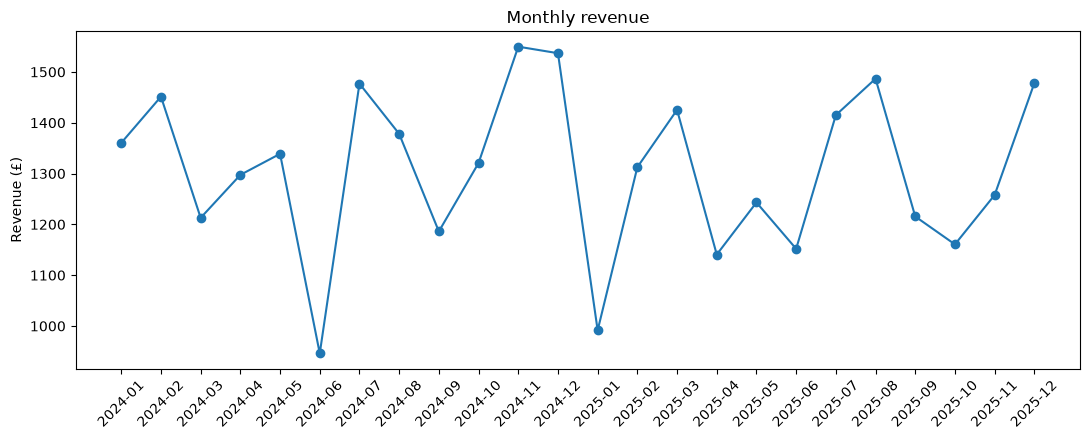

Best month : 2024-11 1550
Worst month: 2024-06 946


In [21]:
monthly = sales.groupby("year_month")["net_sales_gbp"].sum()

plt.figure(figsize=(11, 4.5))
plt.plot(monthly.index.astype(str), monthly.values, marker="o")
plt.title("Monthly revenue")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Best month :", monthly.idxmax(), round(monthly.max()))
print("Worst month:", monthly.idxmin(), round(monthly.min()))

# Revenue by Category

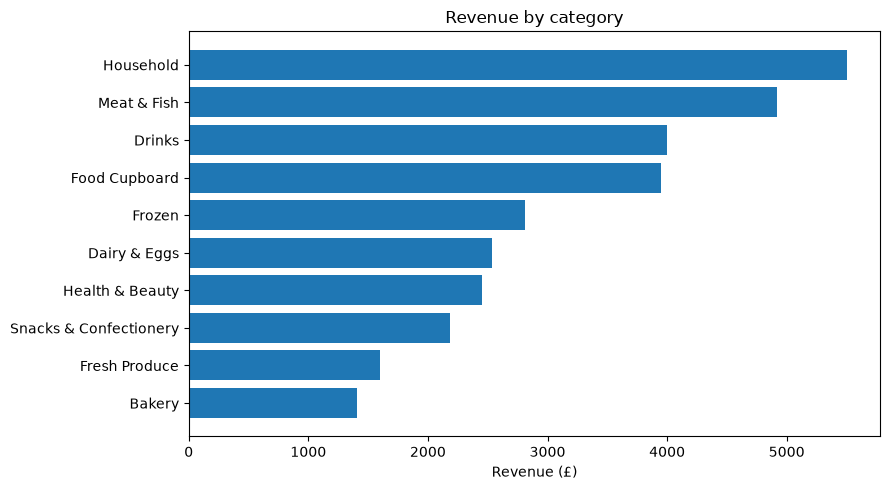

category
Household                 17.5
Meat & Fish               15.7
Drinks                    12.8
Food Cupboard             12.6
Frozen                     9.0
Dairy & Eggs               8.1
Health & Beauty            7.8
Snacks & Confectionery     7.0
Fresh Produce              5.1
Bakery                     4.5
Name: net_sales_gbp, dtype: float64

In [22]:
by_category = sales.groupby("category")["net_sales_gbp"].sum().sort_values()

plt.figure(figsize=(9, 5))
plt.barh(by_category.index, by_category.values)
plt.title("Revenue by category")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.show()

share = (by_category / by_category.sum() * 100).round(1)
share.sort_values(ascending=False)

# Top 10 products

In [23]:
category_stats = sales.groupby("category").agg(
    items=("quantity", "sum"),
    avg_price=("unit_price_gbp", "mean"),
    revenue=("net_sales_gbp", "sum"),
).round(2)

category_stats.sort_values("revenue", ascending=False)

,items,avg_price,revenue
category,,,
Household,1280,4.73,5504.89
Meat & Fish,1308,4.34,4918.60
Drinks,1226,3.75,4000.08
Food Cupboard,1323,3.17,3946.53
Frozen,1203,2.48,2815.85
Dairy & Eggs,1147,2.57,2532.76
Health & Beauty,1281,2.12,2454.71
Snacks & Confectionery,1270,1.95,2185.56
Fresh Produce,1161,1.58,1602.04


# Sales Channels

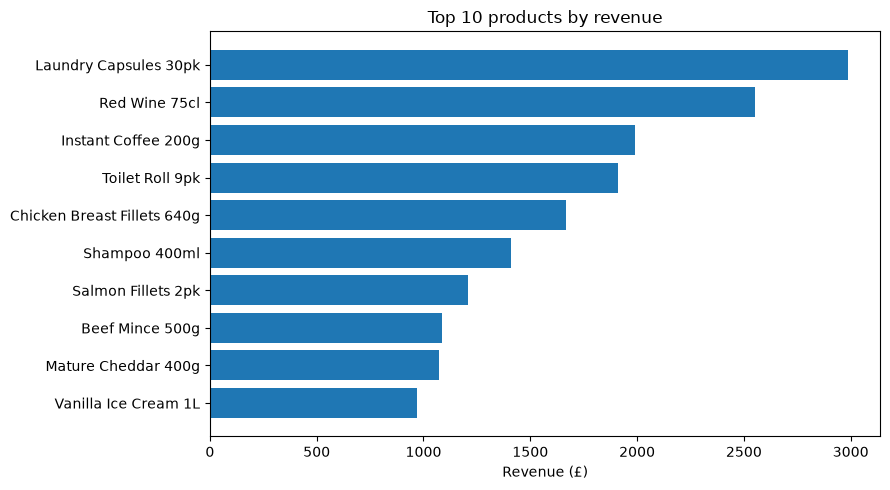

product_name
Shampoo 400ml              461
Washing Up Liquid 900ml    451
Crisps Multipack 6pk       439
Digestive Biscuits 400g    430
Toilet Roll 9pk            417
Name: quantity, dtype: int64

In [24]:
top_revenue = sales.groupby("product_name")["net_sales_gbp"].sum().nlargest(10)

plt.figure(figsize=(9, 5))
plt.barh(top_revenue.index[::-1], top_revenue.values[::-1])
plt.title("Top 10 products by revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.show()

top_qty = sales.groupby("product_name")["quantity"].sum().nlargest(5)
top_qty

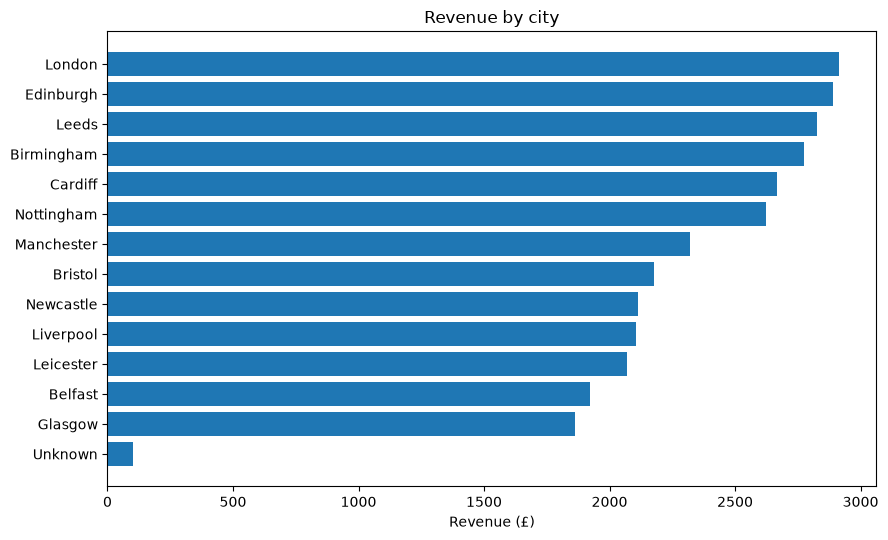

country
England             22009.98
Scotland             4753.02
Wales                2677.62
Northern Ireland     1929.37
Name: net_sales_gbp, dtype: float64

In [25]:
by_city = sales.groupby("city")["net_sales_gbp"].sum().sort_values()

plt.figure(figsize=(9, 5.5))
plt.barh(by_city.index, by_city.values)
plt.title("Revenue by city")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.show()

sales.groupby("country")["net_sales_gbp"].sum().sort_values(ascending=False).round(2)

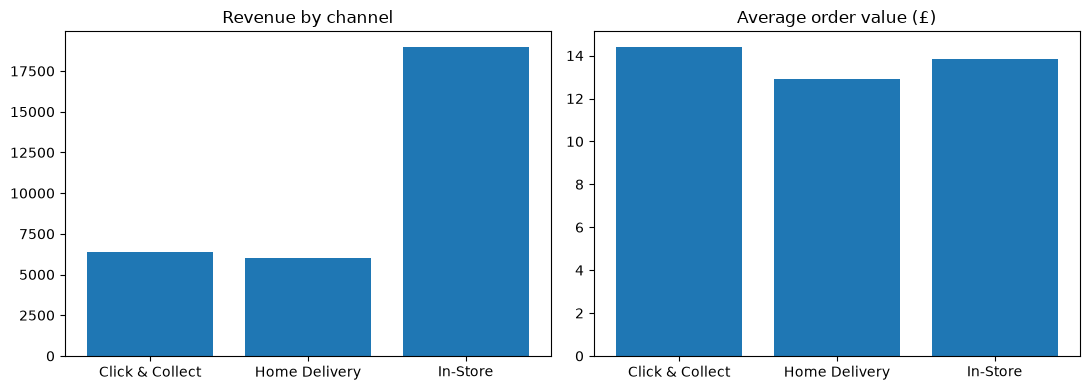

,revenue,orders,avg_order,share_%
channel,,,,
Click & Collect,6369.85,442,14.41,20.31
Home Delivery,6011.98,466,12.90,19.16
In-Store,18988.16,1374,13.82,60.53


In [26]:
by_channel = sales.groupby("channel").agg(
    revenue=("net_sales_gbp", "sum"),
    orders=("transaction_id", "nunique"),
)
by_channel["avg_order"] = by_channel["revenue"] / by_channel["orders"]
by_channel["share_%"] = by_channel["revenue"] / by_channel["revenue"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(by_channel.index, by_channel["revenue"])
axes[0].set_title("Revenue by channel")
axes[1].bar(by_channel.index, by_channel["avg_order"])
axes[1].set_title("Average order value (£)")
plt.tight_layout()
plt.show()

by_channel.round(2)

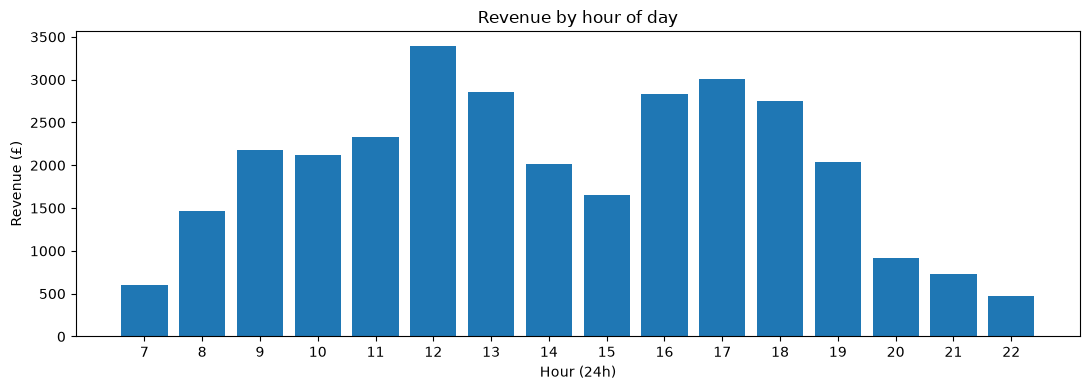

Busiest hour: 12


In [27]:
by_hour = sales.groupby("hour")["net_sales_gbp"].sum()

plt.figure(figsize=(11, 4))
plt.bar(by_hour.index, by_hour.values)
plt.xticks(by_hour.index)
plt.title("Revenue by hour of day")
plt.xlabel("Hour (24h)")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()

print("Busiest hour:", by_hour.idxmax())


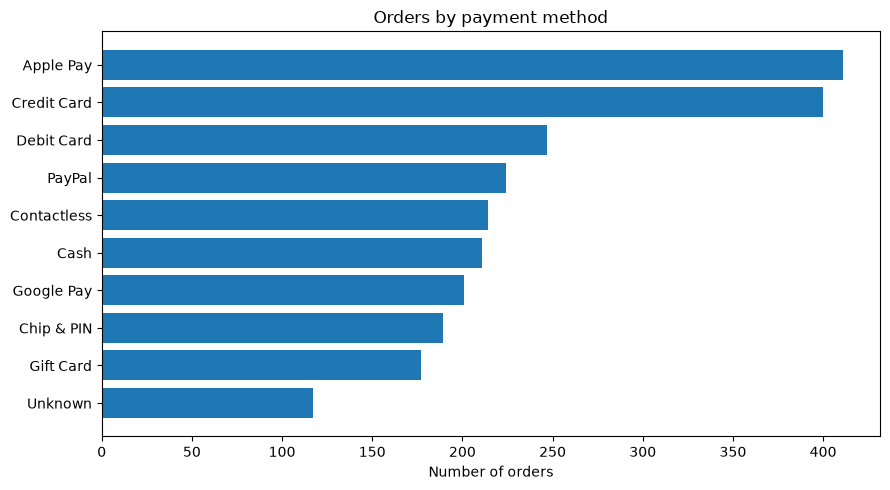

payment_method
Apple Pay      17.2
Credit Card    16.7
Debit Card     10.3
PayPal          9.4
Contactless     9.0
Cash            8.8
Google Pay      8.4
Chip & PIN      7.9
Gift Card       7.4
Unknown         4.9
Name: transaction_id, dtype: float64

In [28]:
by_payment = sales.groupby("payment_method")["transaction_id"].nunique().sort_values()

plt.figure(figsize=(9, 5))
plt.barh(by_payment.index, by_payment.values)
plt.title("Orders by payment method")
plt.xlabel("Number of orders")
plt.tight_layout()
plt.show()

(by_payment / by_payment.sum() * 100).round(1).sort_values(ascending=False)

In [29]:
orders_only = sales.drop_duplicates("transaction_id")

cash_by_age = pd.crosstab(orders_only["age_band"], orders_only["payment_method"] == "Cash", normalize="index") * 100
cash_by_age[True].round(1)


age_band
18-24      10.1
25-34       7.4
35-44       8.6
45-54       5.9
55-64      10.7
65+        10.5
Unknown    10.7
Name: True, dtype: float64

# Promotion

In [30]:
promo = sales.groupby("promotion_type").agg(
    revenue=("net_sales_gbp", "sum"),
    discount=("discount_gbp", "sum"),
    lines=("line_id", "count"),
).sort_values("revenue", ascending=False).round(2)

promo["discount_per_£_revenue"] = (promo["discount"] / promo["revenue"]).round(2)
promo

,revenue,discount,lines,discount_per_£_revenue
promotion_type,,,,
No Promotion,22695.01,0.00,4735,0.00
Multibuy 3 for 2,3352.80,479.56,831,0.14
Half Price,2008.80,2008.58,874,1.00
Loyalty Price,1860.54,407.99,498,0.22
Meal Deal,773.76,331.53,268,0.43
Reduced to Clear,679.08,709.37,320,1.04


# Refunds

In [31]:
refunds = df[df["transaction_status"] == "Refunded"]
print("Total refunded:", round(refunds["net_sales_gbp"].sum(), 2))

refund_table = pd.DataFrame({
    "refunded": refunds.groupby("category")["net_sales_gbp"].sum(),
    "revenue": sales.groupby("category")["net_sales_gbp"].sum(),
})
refund_table["refund_rate_%"] = refund_table["refunded"] / refund_table["revenue"] * 100

refund_table.sort_values("refund_rate_%", ascending=False).round(1)


Total refunded: 1347.87


,refunded,revenue,refund_rate_%
category,,,
Frozen,162.7,2815.8,5.8
Household,298.6,5504.9,5.4
Snacks & Confectionery,116.6,2185.6,5.3
Meat & Fish,232.9,4918.6,4.7
Dairy & Eggs,108.7,2532.8,4.3
Health & Beauty,92.6,2454.7,3.8
Fresh Produce,60.3,1602.0,3.8
Drinks,123.9,4000.1,3.1
Food Cupboard,116.8,3946.5,3.0


# Key Insights

## Summary
- Total revenue: £31,370 from 2,282 orders (2024-2025)
- Average order value: £13.75

## Findings
1. **Seasonality:** Sales peak in November-December (Christmas) and drop sharply in January.
2. **Categories:** Household is the top category (17.5%). All categories sell a similar number of items; the revenue gap comes from price, not volume.
3. **Products:** Laundry Capsules bring the most revenue. Toilet Roll and Shampoo are in the top lists for both revenue and quantity.
4. **Cities:** Sales are balanced across cities. London, Edinburgh and Leeds are the top 3, only £88 apart.
5. **Channels:** In-Store brings 61% of revenue. Click & Collect has a slightly higher basket (£14.41 vs £13.82), but the gap is small.
6. **Time of day:** Two peaks: lunchtime (12:00) and after work (16:00-18:00).
7. **Payments:** Apple Pay and cards lead. Cash is still used by about 10% of customers in every age group.
8. **Promotions:** Multibuy 3 for 2 is the most efficient offer (14p discount per £1 of sales). Half Price costs as much as it earns.
9. **Refunds:** Frozen has the highest refund rate (5.8%).

## Recommendations
- Add staff at 11:30-13:30 and 16:00-18:30; restock shelves during the 14:00-15:00 dip.
- Plan stock for the Christmas peak; run offers in January to soften the drop.
- Use more Multibuy offers; review whether Half Price brings extra spending.
- Keep accepting cash.
- Investigate Frozen refunds (possible cold-chain or delivery issue).
- 